# Regional flood hazard preprocessing and simulation

This notebook uses the same preprocessing, population-density, and SCS-CN simulation functions as `simulator.py`. It combines the full Metro Manila layer with the configured provincial layers instead of clipping the data to Quezon City.

Loaded 48 hazard polygons from 16 site layers.
Sites: Metro Manila, Nueva Ecija, Pampanga, Bulacan, Tarlac, Aurora, Zambales, Bataan, Pangasinan, Nueva Vizcaya, Rizal, Quezon, South Cotabato, Sarangani, Davao del Sur, Davao Occidental


hazard_level,Low Hazard (0–0.5 m),Medium Hazard (>0.5–1.5 m),High Hazard (>1.5 m)
site_name,,,
Metro Manila,1,1,1
Nueva Ecija,1,1,1
Pampanga,1,1,1
Bulacan,1,1,1
Tarlac,1,1,1
Aurora,1,1,1
Zambales,1,1,1
Bataan,1,1,1
Pangasinan,1,1,1


,polygons,estimated_population,mean_density_per_sqkm
population_density_class,,,
High population density,6,9079301.05,24576.35
Low population density,21,2727407.76,515.42
Moderate population density,21,7116802.34,1738.40


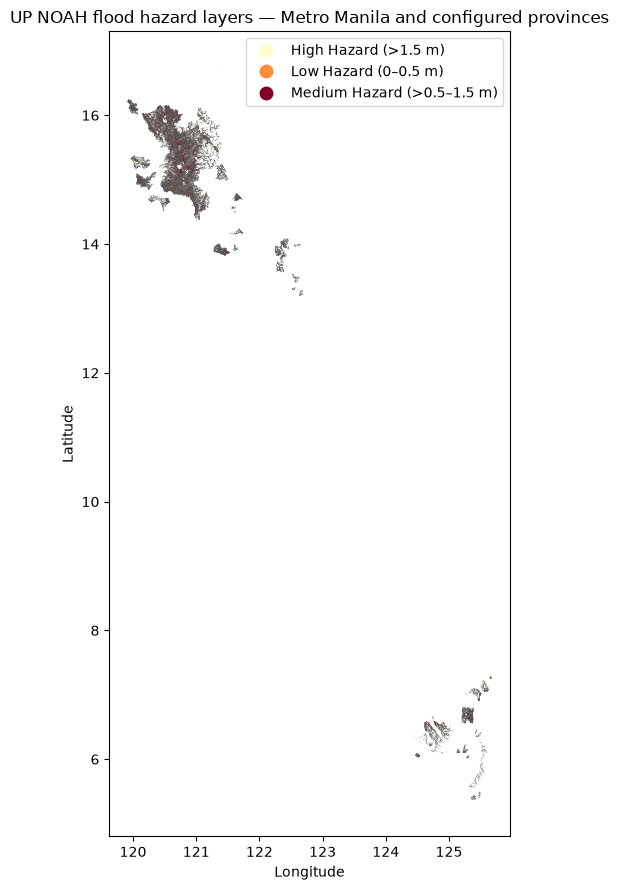

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from simulator import (
    SITE_MAPPING,
    add_population_exposure,
    find_population_raster,
    preprocess_hazard_data,
)

DATA_DIR = Path.cwd()
population_raster_path = find_population_raster(DATA_DIR)
hazard_data = preprocess_hazard_data(DATA_DIR, simplify_tolerance_m=150)
hazard_data = add_population_exposure(hazard_data, population_raster_path)

loaded_sites = hazard_data["site_name"].drop_duplicates().tolist()
print(f"Loaded {len(hazard_data):,} hazard polygons from {len(loaded_sites)} site layers.")
print("Sites:", ", ".join(loaded_sites))

if hazard_data.attrs.get("missing_sites"):
    print("Missing archives:", ", ".join(hazard_data.attrs["missing_sites"]))
if hazard_data.attrs.get("source_errors"):
    print("Source errors:", " | ".join(hazard_data.attrs["source_errors"]))

display(
    hazard_data.groupby(["site_name", "hazard_level"], sort=False)
    .size()
    .unstack(fill_value=0)
)

display(
    hazard_data.groupby("population_density_class", sort=False)
    .agg(
        polygons=("population_estimate", "size"),
        estimated_population=("population_estimate", "sum"),
        mean_density_per_sqkm=("population_density_per_sqkm", "mean"),
    )
    .round(2)
)

fig, ax = plt.subplots(figsize=(12, 9))
hazard_data.plot(
    ax=ax,
    column="hazard_level",
    categorical=True,
    cmap="YlOrRd",
    linewidth=0.15,
    edgecolor="#555555",
    legend=True,
)
ax.set_title("UP NOAH flood hazard layers — Metro Manila and configured provinces")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

Event: 150 mm over 3.0 hours; prior 5-day rainfall: 20 mm
Total flooded area: 7,828.02 km²


,site_name,polygons,mapped_area_sqkm,maximum_depth_m,flooded_area_sqkm,mapped_population,affected_population
0,Metro Manila,3,235.26,1.47,235.26,7811658.14,7811658.14
1,Nueva Ecija,3,1763.80,1.47,1763.80,1536711.28,1536711.28
2,Pampanga,3,1063.09,1.47,1063.09,1661974.22,1661974.22
3,Bulacan,3,669.08,1.47,669.08,1872994.39,1872994.39
4,Tarlac,3,829.24,1.47,829.24,830386.36,830386.36
5,Aurora,3,41.62,1.47,41.62,2623.90,2623.90
6,Zambales,3,398.95,1.47,398.95,407782.02,407782.02
7,Bataan,3,125.85,1.47,125.85,212807.00,212807.00
8,Pangasinan,3,1269.87,1.47,1269.87,1578888.16,1578888.16
9,Nueva Vizcaya,3,20.68,1.47,20.68,1448.05,1448.05


Estimated people affected by flood depth:


,flood_exposure_class,people_in_class,people_affected
0,No flood,0.00,0.00
1,Low flood,5451809.01,5451809.01
2,Moderate flood,13471702.14,13471702.14
3,High flood,0.00,0.00


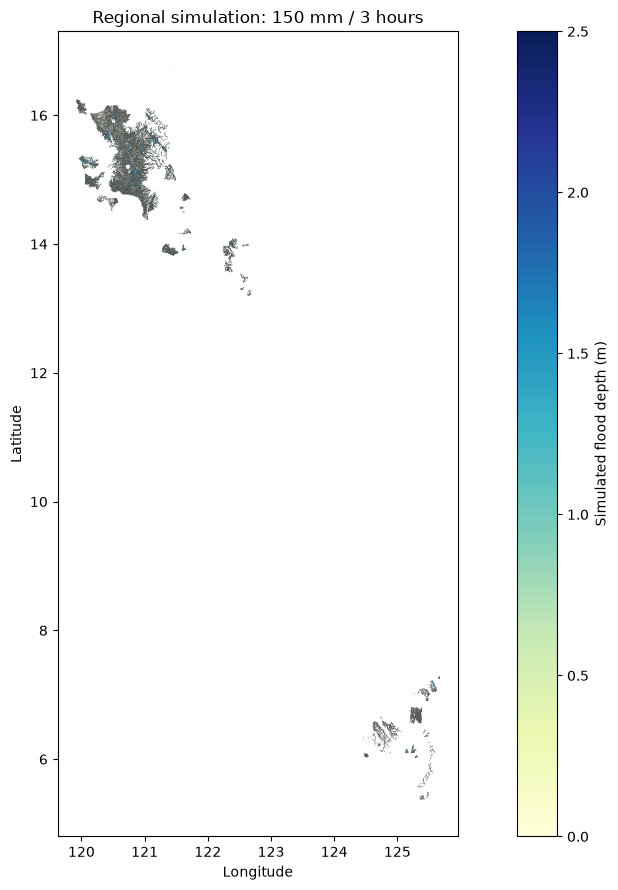

In [8]:
from simulator import (
    flooded_area_sqkm,
    population_impact_summary,
    simulate_flood,
)

# Change these inputs to run a different event across every loaded site.
rain_mm = 150
duration_h = 3.0
prior_rain_mm = 20

simulated_data = simulate_flood(
    hazard_data,
    rain_mm=rain_mm,
    duration_h=duration_h,
    prior_rain_mm=prior_rain_mm,
)
active_data = simulated_data[simulated_data["sim_depth_m"] >= 0.05].copy()

site_summary = (
    simulated_data.groupby("site_name", sort=False)
    .agg(
        polygons=("Var", "size"),
        mapped_area_sqkm=("area_sqkm", "sum"),
        maximum_depth_m=("sim_depth_m", "max"),
    )
    .reset_index()
)
flooded_by_site = active_data.groupby("site_name")["area_sqkm"].sum()
site_summary["flooded_area_sqkm"] = (
    site_summary["site_name"].map(flooded_by_site).fillna(0.0)
)
mapped_population_by_site = simulated_data.groupby("site_name")["population_estimate"].sum()
affected_population_by_site = simulated_data.groupby("site_name")["affected_population"].sum()
site_summary["mapped_population"] = site_summary["site_name"].map(mapped_population_by_site).fillna(0.0)
site_summary["affected_population"] = site_summary["site_name"].map(affected_population_by_site).fillna(0.0)

print(
    f"Event: {rain_mm} mm over {duration_h} hours; "
    f"prior 5-day rainfall: {prior_rain_mm} mm"
)
print(f"Total flooded area: {flooded_area_sqkm(simulated_data):,.2f} km²")
display(site_summary.round(2))

print("Estimated people affected by flood depth:")
display(population_impact_summary(simulated_data).round(2))

fig, ax = plt.subplots(figsize=(12, 9))
simulated_data.plot(
    ax=ax,
    column="sim_depth_m",
    cmap="YlGnBu",
    vmin=0,
    vmax=2.5,
    linewidth=0.15,
    edgecolor="#555555",
    legend=True,
    legend_kwds={"label": "Simulated flood depth (m)"},
)
ax.set_title(f"Regional simulation: {rain_mm} mm / {duration_h:g} hours")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

## Population and flood map

The next cell renders the classified population-density layer, simulated flood polygons, and affected-population flood-depth layer. Run `streamlit run simulator.py` from this folder for the full interactive app.


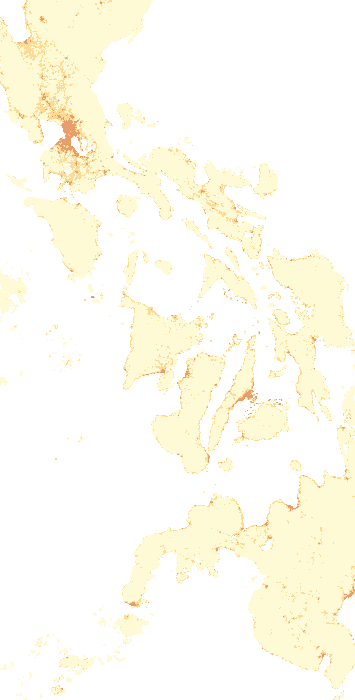

In [9]:
from simulator import build_flood_map

# LayerControl toggles population density, simulated flood polygons,
# and the affected-population depth spectrum independently.
population_map = build_flood_map(
    simulated_data,
    active_data,
    map_mode="Continuous depth spectrum",
    population_raster_path=population_raster_path,
)
display(population_map)